<a href="https://colab.research.google.com/github/yang200212/MSSP-6070/blob/main/Assignments/Assignment%202/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import userdata
import os
import subprocess
from pathlib import Path

owner = "yang200212" # Replace with the GitHub repository owner
repository = "MSSP-6070" # Replace with the GitHub repository name
repo_url = f'https://github.com/{owner}/{repository}.git'
repo_path = Path('/content') / repository

# Clone the repository
import subprocess
subprocess.run(['git', 'clone', repo_url])

# Navigate into the cloned repository directory (optional, but often useful)
os.chdir(repository)
print("Changed directory to: {os.getcwd()}")

Changed directory to: {os.getcwd()}


In [3]:
import subprocess

subprocess.run(
    ['git', '-C', str(repo_path), 'pull', 'origin', 'main'],
    check=True
)

CompletedProcess(args=['git', '-C', '/content/MSSP-6070', 'pull', 'origin', 'main'], returncode=0)

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define dataset path
DATA_PATH = repo_path / 'Assignments' / 'Assignment 2' / 'InternetSales.csv'

# Check whether the file exists
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Data file not found: {DATA_PATH}"
    )

# Load the CSV dataset
sales = pd.read_csv(DATA_PATH, encoding='cp1252')

# Confirm successful loading
print("Data loaded successfully!")
print("Data shape:", sales.shape)
display(sales.head())

Data loaded successfully!
Data shape: (60398, 60)


/tmp/ipykernel_2742/2690320246.py:16: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  sales = pd.read_csv(DATA_PATH, encoding='cp1252')


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [5]:
# Add Year variable to facilitate later analysis

# Convert date to datetime
sales["OrderDate"] = pd.to_datetime(sales["OrderDate"])
# Create Year variable
sales["Year"] = sales["OrderDate"].dt.year

# Check dataset
print("Dataset shape:", sales.shape)
display(sales.head())
print(sales.columns.tolist())

Dataset shape: (60398, 61)


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate,Year
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,2011-01-19,1/31/2011,1/26/2011,2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,2013-01-18,1/30/2013,1/25/2013,2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,21.98,1.7584,0.5495,NaN,NaN,2013-01-18,1/30/2013,1/25/2013,2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,2013-05-03,5/15/2013,5/10/2013,2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,28.99,2.3192,0.7248,NaN,NaN,2013-05-03,5/15/2013,5/10/2013,2013


['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode', 'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title', 'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate', 'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome', 'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation', 'SpanishEducation', 'FrenchEducation', 'EnglishOccupation', 'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag', 'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone', 'DateFirstPurchase', 'CommuteDistance', 'ProductKey', 'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey', 'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey', 'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber', 'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct', 'DiscountAmount', 'ProductStandardCost', 'TotalProductCost', 'SalesAmount', 'TaxAmt', 'Freight', 'CarrierTrackingNumber', 'CustomerPONumber', 'OrderDate', 'DueDate', 'ShipDat

EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
Year,,,,,,
2010,20909.78,3578.27,3399.99,0.00,699.10,14833.90
2011,2563732.25,571571.80,410845.33,520500.16,550591.22,2458285.17
2012,2128407.46,307604.52,648065.54,608657.98,712700.96,1437048.73
2013,4339443.38,1085632.65,1578511.80,1761876.36,2124007.29,5462078.86
2014,8507.72,9457.62,3195.06,3277.83,3713.64,17542.85


,SalesAmount
EnglishCountryRegionName,
United States,9389789.51
Australia,9061000.58
United Kingdom,3391712.21
Germany,2894312.34
France,2644017.71
Canada,1977844.86


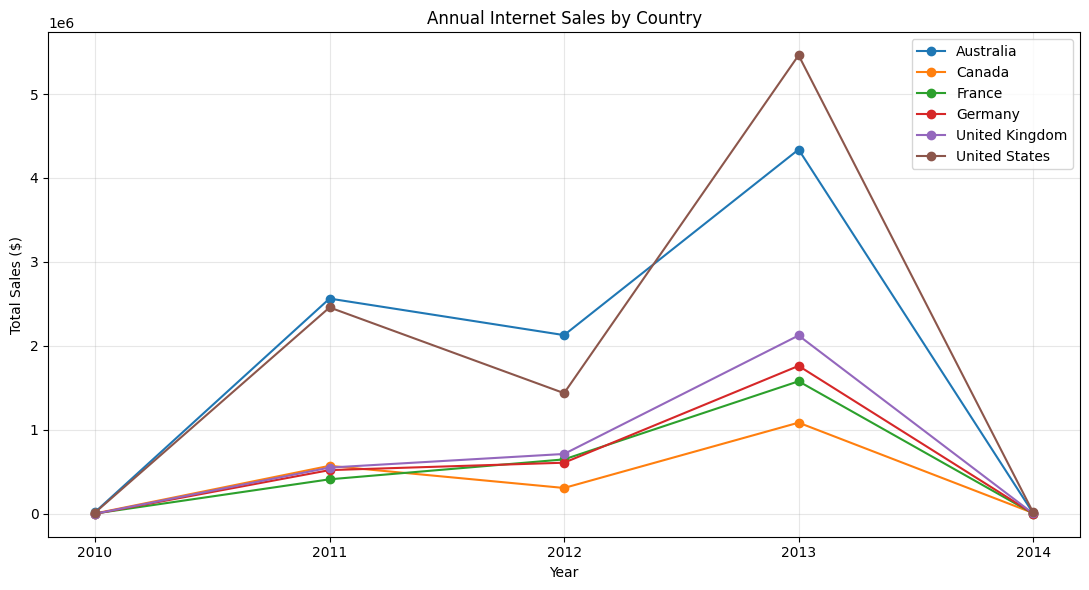

In [25]:
# Question 1: What are the internet sales (SalesAmount) by year for each country (EnglishCountryRegionName)
# region?

# Calculate annual sales by country
sales_by_country = (
    sales.groupby(["Year", "EnglishCountryRegionName"])["SalesAmount"]
    .sum()
    .reset_index()
)

# Create a pivot table
sales_pivot = sales_by_country.pivot(
    index="Year",
    columns="EnglishCountryRegionName",
    values="SalesAmount"
).fillna(0)
display(sales_pivot.round(2))

# Calculate total sales by country
country_total = (
    sales.groupby("EnglishCountryRegionName")["SalesAmount"]
    .sum()
    .sort_values(ascending=False)
)
display(country_total.round(2))

# Graph: annual sales trends
plt.figure(figsize=(11, 6))

for country in sales_pivot.columns:
    plt.plot(
        sales_pivot.index,
        sales_pivot[country],
        marker="o",
        label=country
    )

plt.title("Annual Internet Sales by Country")
plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.xticks(sales_pivot.index)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


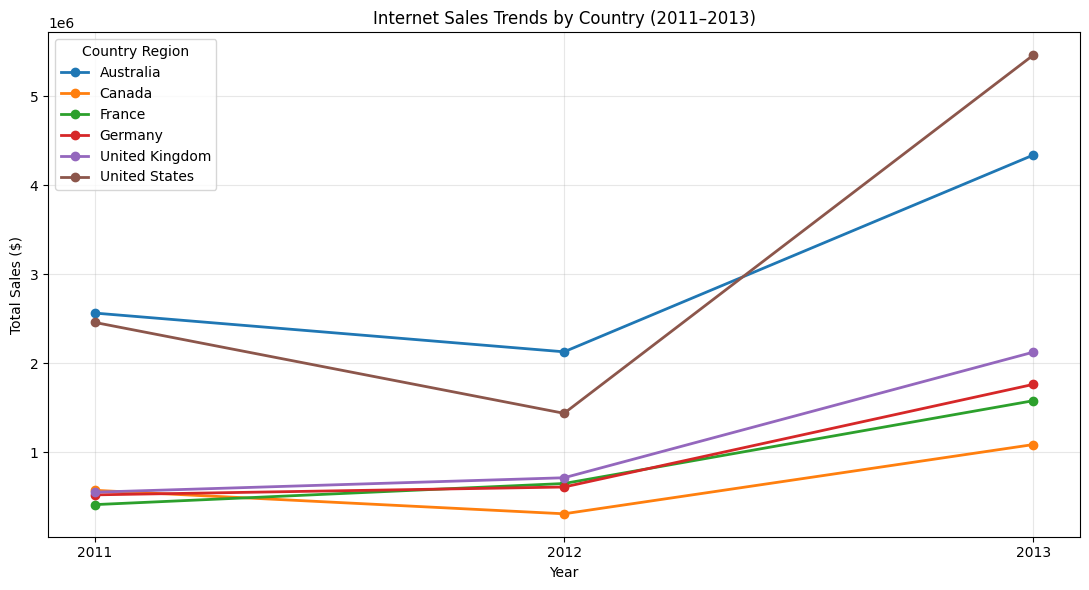

In [13]:
# Since data is incomplete for year 2010 and 2014, I exclude them from the trend analysis
sales_2011_2013 = sales_pivot.loc[2011:2013]

# Plot sales trends for complete years only
plt.figure(figsize=(11, 6))

for country in sales_2011_2013.columns:
    plt.plot(
        sales_2011_2013.index,
        sales_2011_2013[country],
        marker="o",
        linewidth=2,
        label=country
    )

plt.title("Internet Sales Trends by Country (2011–2013)")
plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.xticks([2011, 2012, 2013])
plt.legend(title="Country Region")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# There is a slight drop of sales amount from 2011 to 2012, but significant growth from 2012 to 2013

In [26]:
# Customer Analysis
# Question 2: Generate summary statistics for Yearly Income and Gender by Country Regions

# One observation per customer because a customer may conduct multiple purchases
customers = sales.drop_duplicates(subset="CustomerKey").copy()

# Summary statistics of Yearly Income by country and gender
income_summary = (
    customers.groupby(["EnglishCountryRegionName", "Gender"])
    ["YearlyIncome"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
)

print("Yearly Income Summary Statistics:")
display(income_summary)

Yearly Income Summary Statistics:


count      mean   median    min     max  \
EnglishCountryRegionName Gender                                            
Australia                F        1777  65284.19  70000.0  10000  160000   
                         M        1814  63412.35  70000.0  10000  170000   
Canada                   F         767  56505.87  60000.0  10000  170000   
                         M         804  57798.51  60000.0  10000  170000   
France                   F         893  35341.55  30000.0  10000  110000   
                         M         917  36172.30  30000.0  10000  110000   
Germany                  F         874  43810.07  30000.0  10000  130000   
                         M         906  42108.17  30000.0  10000  130000   
United Kingdom           F         934  52184.15  30000.0  10000  170000   
                         M         979  52155.26  30000.0  10000  170000   
United States            F        3888  63276.75  60000.0  10000  170000   
                         M        3931  63953.19  60000.0  10000  170000   

                                      std  
EnglishCountryRegionName Gender            
Australia                F       31164.36  
                         M       32450.71  
Canada                   F       19181.55  
                         M       21214.77  
France                   F       26915.85  
                         M       27633.45  
Germany                  F       35715.76  
                         M       35277.49  
United Kingdom           F       48288.44  
                         M       48593.22  
United States            F       25166.56  
                         M       26228.43

Gender Counts by Country:


Gender,F,M
EnglishCountryRegionName,,
Australia,1777,1814
Canada,767,804
France,893,917
Germany,874,906
United Kingdom,934,979
United States,3888,3931


Gender Percentages by Country:


Gender,F,M
EnglishCountryRegionName,,
Australia,49.48,50.52
Canada,48.82,51.18
France,49.34,50.66
Germany,49.10,50.90
United Kingdom,48.82,51.18
United States,49.73,50.27


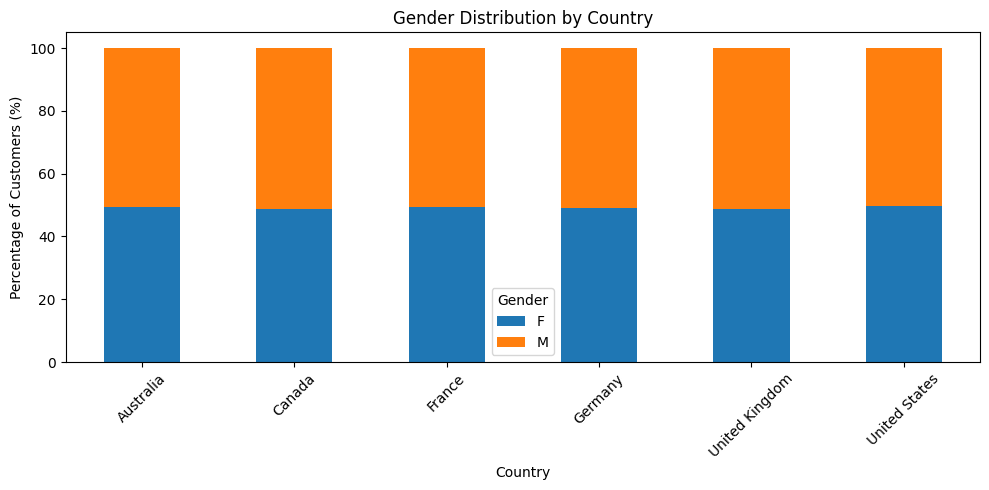

In [15]:
# Gender counts by country
gender_counts = pd.crosstab(
    customers["EnglishCountryRegionName"],
    customers["Gender"]
)

print("Gender Counts by Country:")
display(gender_counts)

# Gender percentages by country
gender_percent = (
    gender_counts.div(gender_counts.sum(axis=1), axis=0) * 100
)

print("Gender Percentages by Country:")
display(gender_percent.round(2))

# Explore gender distribution
gender_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Gender Distribution by Country")
plt.xlabel("Country")
plt.ylabel("Percentage of Customers (%)")
plt.legend(title="Gender")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# Approximately equal distribution across gender

In [16]:
# Question 3: What is the average price of the product category that generates the most sales?

# Explore product names
unique_products = (
    sales["EnglishProductName"]
    .dropna()
    .drop_duplicates()
    .sort_values()
)

print("Number of unique products:", len(unique_products))

# Display product names
display(unique_products.reset_index(drop=True))

Number of unique products: 130


,EnglishProductName
0,AWC Logo Cap
1,All-Purpose Bike Stand
2,Bike Wash - Dissolver
3,"Classic Vest, L"
4,"Classic Vest, M"
...,...
125,"Touring-3000 Yellow, 62"
126,Water Bottle - 30 oz.
127,"Women's Mountain Shorts, L"
128,"Women's Mountain Shorts, M"


In [17]:
# Explore common naming patterns
keywords = [
    "Road-", "Mountain-", "Touring-",
    "Jersey", "Gloves", "Shorts",
    "Helmet", "Tire", "Bottle"
]

for keyword in keywords:
    matches = unique_products[
        unique_products.str.contains(
            keyword, case=False, regex=False
        )
    ]

    print(f"\n{keyword}: {len(matches)} products")
    print(matches.head(3).tolist())


Road-: 38 products
['Road-150 Red, 44', 'Road-150 Red, 48', 'Road-150 Red, 52']

Mountain-: 28 products
['Mountain-100 Black, 38', 'Mountain-100 Black, 42', 'Mountain-100 Black, 44']

Touring-: 22 products
['Touring-1000 Blue, 46', 'Touring-1000 Blue, 50', 'Touring-1000 Blue, 54']

Jersey: 8 products
['Long-Sleeve Logo Jersey, L', 'Long-Sleeve Logo Jersey, M', 'Long-Sleeve Logo Jersey, S']

Gloves: 3 products
['Half-Finger Gloves, L', 'Half-Finger Gloves, M', 'Half-Finger Gloves, S']

Shorts: 3 products
["Women's Mountain Shorts, L", "Women's Mountain Shorts, M", "Women's Mountain Shorts, S"]

Helmet: 3 products
['Sport-100 Helmet, Black', 'Sport-100 Helmet, Blue', 'Sport-100 Helmet, Red']

Tire: 10 products
['HL Mountain Tire', 'HL Road Tire', 'LL Mountain Tire']

Bottle: 3 products
['Mountain Bottle Cage', 'Road Bottle Cage', 'Water Bottle - 30 oz.']


In [18]:
# Create product categories based on product names
product = sales["EnglishProductName"].str.lower()

sales["ProductCategory"] = np.select(
    [
        product.str.startswith("road-"),
        product.str.startswith("mountain-"),
        product.str.startswith("touring-"),
        product.str.contains(
            "jersey|gloves|shorts|vest|cap|socks",
            na=False
        )
    ],
    [
        "Road Bikes",
        "Mountain Bikes",
        "Touring Bikes",
        "Clothing"
    ],
    default="Accessories"
)

# Check number of unique products in each category
category_count = (
    sales.groupby("ProductCategory")["EnglishProductName"]
    .nunique()
    .sort_values(ascending=False)
)

display(category_count)

# Review the product names assigned to Accessories
accessory_products = (
    sales.loc[
        sales["ProductCategory"] == "Accessories",
        "EnglishProductName"
    ]
    .drop_duplicates()
    .sort_values()
)

print("Products classified as Accessories:")
display(accessory_products.reset_index(drop=True))

,EnglishProductName
ProductCategory,
Road Bikes,38
Mountain Bikes,28
Accessories,22
Touring Bikes,22
Clothing,20


Products classified as Accessories:


,EnglishProductName
0,All-Purpose Bike Stand
1,Bike Wash - Dissolver
2,Fender Set - Mountain
3,HL Mountain Tire
4,HL Road Tire
5,Hitch Rack - 4-Bike
6,Hydration Pack - 70 oz.
7,LL Mountain Tire
8,LL Road Tire
9,ML Mountain Tire


In [24]:
# Now I can explore the avg price of the product category that generates the most sales

# Summarize product category performance
category_summary = (
    sales.groupby("ProductCategory")
    .agg(
        TotalSales=("SalesAmount", "sum"),
        UnitsSold=("OrderQuantity", "sum"),
        AveragePrice=("UnitPrice", "mean"),
        TotalCost=("TotalProductCost", "sum")
    )
)

# Calculate revenue share
category_summary["SalesSharePct"] = (
    category_summary["TotalSales"]
    / category_summary["TotalSales"].sum() * 100
)

# Calculate gross profit
category_summary["GrossProfit"] = (
    category_summary["TotalSales"]
    - category_summary["TotalCost"]
)

# Calculate gross margin
category_summary["GrossMarginPct"] = (
    category_summary["GrossProfit"]
    / category_summary["TotalSales"] * 100
)

# Sort categories by total sales
category_summary = category_summary.sort_values(
    "TotalSales", ascending=False
)

print("Product Category Sales Summary:")
display(category_summary.round(2))

# Identify highest-selling category
top_category = category_summary.index[0]
average_price = category_summary.loc[
    top_category, "AveragePrice"
]

print("Highest-selling category:", top_category)
print(f"Average unit price: ${average_price:,.2f}")


Product Category Sales Summary:


,TotalSales,UnitsSold,AveragePrice,TotalCost,SalesSharePct,GrossProfit,GrossMarginPct
ProductCategory,,,,,,,
Road Bikes,14520584.04,8068,1799.77,8983284.34,49.46,5537299.70,38.13
Mountain Bikes,9952759.56,4970,2002.57,5439135.46,33.90,4513624.11,45.35
Touring Bikes,3844801.05,2167,1774.25,2389928.35,13.10,1454872.70,37.84
Accessories,700759.96,36092,19.42,262085.39,2.39,438674.57,62.60
Clothing,339772.61,9101,37.33,203360.03,1.16,136412.58,40.15


Highest-selling category: Road Bikes
Average unit price: $1,799.77


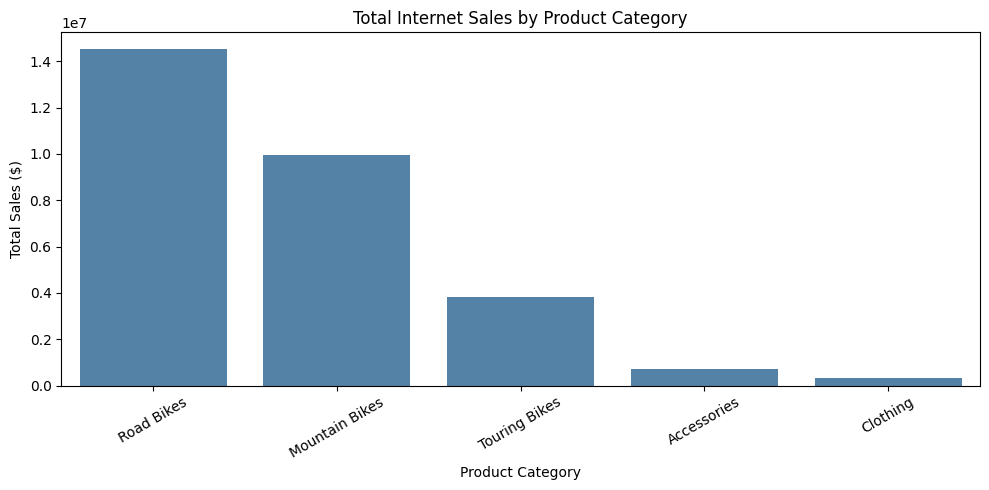

Annual Sales by Product Category:


ProductCategory,Accessories,Clothing,Mountain Bikes,Road Bikes,Touring Bikes
Year,,,,,
2010,0.00,0.00,16974.95,26446.09,0.00
2011,0.00,0.00,1332364.80,5743161.12,0.00
2012,2147.08,642.79,2263420.53,3554883.92,21390.87
2013,668241.53,323806.45,6339999.28,5196092.90,3823410.18
2014,30371.35,15323.37,0.00,0.00,0.00


In [21]:
# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_summary.reset_index(),
    x="ProductCategory",
    y="TotalSales",
    color="steelblue"
)

plt.title("Total Internet Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Annual sales by product category
category_year = sales.pivot_table(
    index="Year",
    columns="ProductCategory",
    values="SalesAmount",
    aggfunc="sum",
    fill_value=0
)

print("Annual Sales by Product Category:")
display(category_year.round(2))

Homeownership and Sales Summary:


,Customers,TotalSales,AvgSalesPerCustomer,MedianSalesPerCustomer,StdSalesPerCustomer,AvgOrdersPerCustomer,AvgYearlyIncome,AvgOrderValue
HouseOwnerFlag,,,,,,,,
Non-homeowners,5982,8973327.42,1500.05,209.96,2046.88,1.44,55172.18,1043.29
Homeowners,12502,20385349.80,1630.57,342.00,2159.07,1.52,58326.67,1069.65


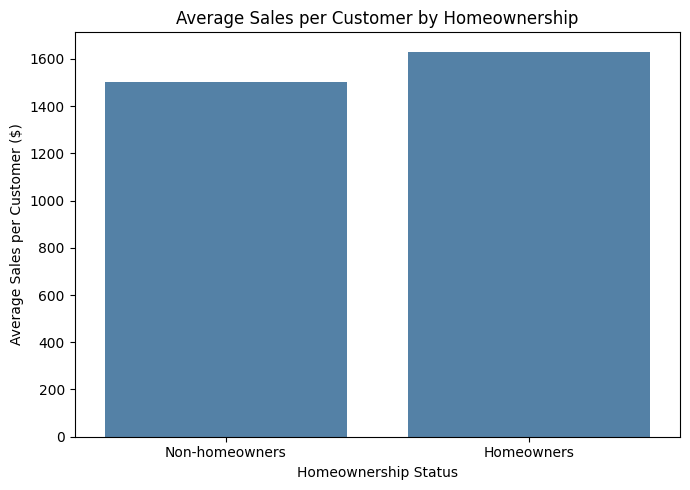

Homeownership Comparison Within Income Groups:


count     mean  median
IncomeBracket HouseOwnerFlag                        
<=40k         0                2930  1077.88  115.49
              1                5026  1471.88  539.99
40-70k        0                1700  1721.16  607.96
              1                4446  1483.21  539.99
70-100k       0                 780  2216.42  564.34
              1                1975  1925.43  155.47
>100k         0                 572  2028.59  539.99
              1                1055  2455.55  597.26

In [22]:
# Question 4: Does owning a home make a difference in sales?

# Aggregate sales at customer level
customer_sales = (
    sales.groupby(
        ["CustomerKey", "HouseOwnerFlag", "YearlyIncome"],
        as_index=False
    )
    .agg(
        CustomerSales=("SalesAmount", "sum"),
        OrderCount=("SalesOrderNumber", "nunique")
    )
)

# Compare homeowners and non-homeowners
home_summary = (
    customer_sales.groupby("HouseOwnerFlag")
    .agg(
        Customers=("CustomerKey", "nunique"),
        TotalSales=("CustomerSales", "sum"),
        AvgSalesPerCustomer=("CustomerSales", "mean"),
        MedianSalesPerCustomer=("CustomerSales", "median"),
        StdSalesPerCustomer=("CustomerSales", "std"),
        AvgOrdersPerCustomer=("OrderCount", "mean"),
        AvgYearlyIncome=("YearlyIncome", "mean")
    )
)

# Calculate average order value
orders = (
    sales.groupby(["HouseOwnerFlag", "SalesOrderNumber"])
    ["SalesAmount"]
    .sum()
    .reset_index()
)

avg_order_value = (
    orders.groupby("HouseOwnerFlag")["SalesAmount"]
    .mean()
)

home_summary["AvgOrderValue"] = avg_order_value

home_summary = home_summary.rename(
    index={0: "Non-homeowners", 1: "Homeowners"}
)

print("Homeownership and Sales Summary:")
display(home_summary.round(2))

# Compare average sales per customer
plt.figure(figsize=(7, 5))

sns.barplot(
    x=home_summary.index,
    y=home_summary["AvgSalesPerCustomer"],
    color="steelblue"
)

plt.title("Average Sales per Customer by Homeownership")
plt.xlabel("Homeownership Status")
plt.ylabel("Average Sales per Customer ($)")
plt.tight_layout()
plt.show()

# Compare homeowners within income brackets
customer_sales["IncomeBracket"] = pd.cut(
    customer_sales["YearlyIncome"],
    bins=[0, 40000, 70000, 100000, np.inf],
    labels=["<=40k", "40-70k", "70-100k", ">100k"]
)

income_home = (
    customer_sales.groupby(
        ["IncomeBracket", "HouseOwnerFlag"],
        observed=True
    )["CustomerSales"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print("Homeownership Comparison Within Income Groups:")
display(income_home)

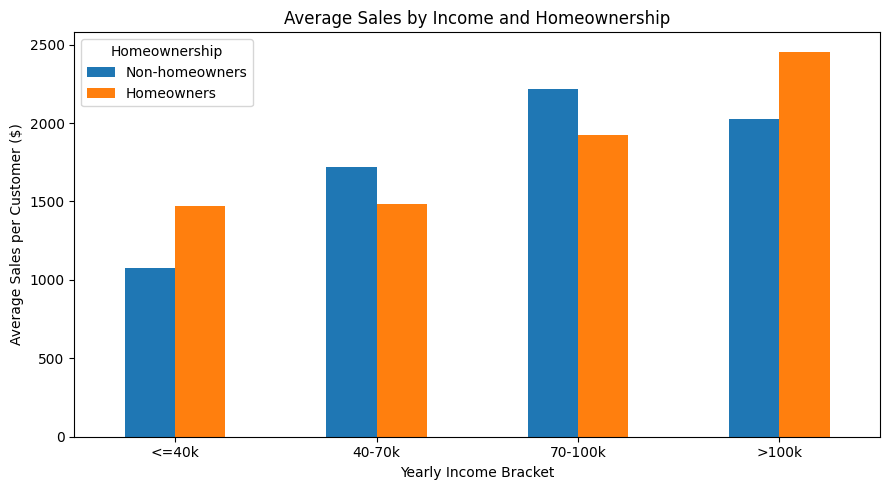

In [23]:
# Plot average sales by income bracket and homeownership
income_plot = (
    customer_sales.groupby(
        ["IncomeBracket", "HouseOwnerFlag"],
        observed=True
    )["CustomerSales"]
    .mean()
    .unstack()
)

income_plot = income_plot.rename(
    columns={0: "Non-homeowners", 1: "Homeowners"}
)

income_plot.plot(kind="bar", figsize=(9, 5))

plt.title("Average Sales by Income and Homeownership")
plt.xlabel("Yearly Income Bracket")
plt.ylabel("Average Sales per Customer ($)")
plt.xticks(rotation=0)
plt.legend(title="Homeownership")
plt.tight_layout()
plt.show()